# 06 · Simulación what-if: espera de cama para hospitalización (SimPy)
El cuello de botella principal es la **espera en urgencias de los pacientes que se van a hospitalizar**
(mediana 16,7 h, P90 64 h). Se modela como una cola de camas:

- **Llegadas**: solicitud de cama = llegada a urgencias + tiempo clínico de urgencias (muestreado de los
  pacientes en observación que no se hospitalizan) · hospitalizaciones directas sin tiempo clínico.
- **Servicio**: estancia hospitalaria observada (empírica, último año).
- **Capacidad**: nº de camas *efectivas*, calibrado para reproducir la espera excedente observada
  (espera hasta cama − tiempo clínico). No hay dato oficial de camas: es una estimación.
- Números aleatorios comunes: base y escenarios reciben los mismos pacientes.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import datos, flow
from src.config import FIGURES, DATA_INTERIM, DATA_PROCESSED, ETAPAS
pd.set_option("display.max_columns", 50); pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIGURES / f"{nombre}.png", dpi=150, bbox_inches="tight"); plt.show()
import simpy

In [2]:
ep = datos.episodios()
ep = ep[(ep.los_atipica == 0) & (ep.inicio >= "2025-05-01")]          # último año
hosp = ep[ep.hospitalizado & ep.h_hospitalizacion.notna() & (ep.h_hospitalizacion > 0)].copy()
obs = ep.loc[ep.tipo_detalle == "Urgencias con observación", "los_h"].values
dias = (ep.inicio.max() - ep.inicio.min()).days
directa = (hosp.primera_etapa == 9201).values
espera_obs = hosp.loc[~directa, "h_hasta_hosp"].mean()
objetivo = max(espera_obs - obs.mean(), 0.5)
lam = len(hosp) / (dias * 24)                         # solicitudes de cama por hora
perfil = hosp.inicio.dt.hour.value_counts(normalize=True).sort_index().reindex(range(24), fill_value=0).values
los_hosp = hosp.h_hospitalizacion.values
p_directa = directa.mean()
print(f"Hospitalizaciones/día: {lam*24:.1f} · estancia hospitalaria media: {los_hosp.mean():.0f} h ({los_hosp.mean()/24:.1f} días)")
print(f"Espera media hasta cama observada: {espera_obs:.1f} h · tiempo clínico medio en urgencias: {obs.mean():.1f} h")
print(f"-> espera EXCEDENTE a reproducir: {objetivo:.1f} h · camas ocupadas promedio (Little): {lam*los_hosp.mean():.0f}")

Hospitalizaciones/día: 48.2 · estancia hospitalaria media: 135 h (5.6 días)
Espera media hasta cama observada: 31.3 h · tiempo clínico medio en urgencias: 12.8 h
-> espera EXCEDENTE a reproducir: 18.5 h · camas ocupadas promedio (Little): 270


In [3]:
def generar(seed, dias_sim, warmup_dias):
    # pacientes pre-generados (Poisson no homogéneo): los mismos para todos los escenarios
    rng = np.random.default_rng(seed); t, pac = 0.0, []
    rmax = lam * 24 * perfil.max()
    while t < (dias_sim + warmup_dias) * 24:
        t += rng.exponential(1 / rmax)
        u_acepta, u_extra, u_dir = rng.random(3)
        clinico = 0.0 if u_dir < p_directa else float(rng.choice(obs))
        pac.append((t, perfil[int(t) % 24] / perfil.max(), u_acepta, u_extra, clinico,
                    float(rng.choice(los_hosp)), float(rng.choice(los_hosp))))
    return pac

def simular(camas, factor_demanda=1.0, factor_los=1.0, reduccion_los_h=0.0, dias_sim=180, seed=0, warmup_dias=60):
    env = simpy.Environment(); res = simpy.Resource(env, capacity=int(camas)); esperas = []
    sol = []
    for t, p_h, u_a, u_e, clin, los, los2 in generar(seed, dias_sim, warmup_dias):
        if u_a <= p_h * min(factor_demanda, 1):
            sol.append((t + clin, los))
            if factor_demanda > 1 and u_e <= factor_demanda - 1:
                sol.append((t + clin + 0.01, los2))
    sol.sort()
    def paciente(t_sol, los):
        yield env.timeout(t_sol - env.now)
        with res.request() as r:
            yield r
            if t_sol >= warmup_dias * 24: esperas.append(env.now - t_sol)
            yield env.timeout(max(los * factor_los - reduccion_los_h, 1.0))
    for tt, ll in sol: env.process(paciente(tt, ll))
    env.run()
    return np.array(esperas)

def resumen(camas, reps=4, **kw):
    w = np.concatenate([simular(camas, seed=s, **kw) for s in range(reps)])
    return {"espera_media_h": w.mean(), "espera_p50_h": np.median(w), "espera_p90_h": np.quantile(w, .9),
            "pct_espera_mayor_12h": (w > 12).mean() * 100}

base_little = int(lam * los_hosp.mean())
calib = pd.Series({c: resumen(c, reps=2)["espera_media_h"] for c in range(base_little - 6, base_little + 40, 3)},
                  name="espera_media_sim_h")
camas = int((calib - objetivo).abs().idxmin())
print(f"Camas efectivas calibradas: {camas} (objetivo {objetivo:.1f} h)"); calib.to_frame()

Camas efectivas calibradas: 273 (objetivo 18.5 h)


,espera_media_sim_h
264,72.82
267,46.48
270,27.70
273,12.86
276,6.93
279,3.60
282,2.00
285,1.15
288,0.70
291,0.44


In [4]:
escenarios = {
    "Base": dict(camas=camas),
    "+10 camas": dict(camas=camas + 10),
    "+20 camas": dict(camas=camas + 20),
    "Estancia hospitalaria -5%": dict(camas=camas, factor_los=0.95),
    "Estancia hospitalaria -10%": dict(camas=camas, factor_los=0.90),
    "Alta 4 h más temprano (gestión de egresos)": dict(camas=camas, reduccion_los_h=4),
    "+10% demanda (temporada respiratoria)": dict(camas=camas, factor_demanda=1.10),
    "+10% demanda y -10% estancia": dict(camas=camas, factor_demanda=1.10, factor_los=0.90),
}
res = pd.DataFrame({k: resumen(**v) for k, v in escenarios.items()}).T
res["cambio_espera_media_%"] = (res.espera_media_h / res.loc["Base", "espera_media_h"] - 1) * 100
res

,espera_media_h,espera_p50_h,espera_p90_h,pct_espera_mayor_12h,cambio_espera_media_%
Base,13.88,6.69,41.18,42.20,0.00
+10 camas,1.96,0.00,7.17,4.90,-85.90
+20 camas,0.33,0.00,0.00,0.49,-97.59
Estancia hospitalaria -5%,0.90,0.00,2.71,2.35,-93.49
Estancia hospitalaria -10%,0.07,0.00,0.00,0.00,-99.52
Alta 4 h más temprano (gestión de egresos),2.98,0.00,10.17,7.92,-78.55
+10% demanda (temporada respiratoria),269.01,252.62,445.41,100.00,"1,838.24"
+10% demanda y -10% estancia,9.20,2.60,26.30,31.04,-33.70


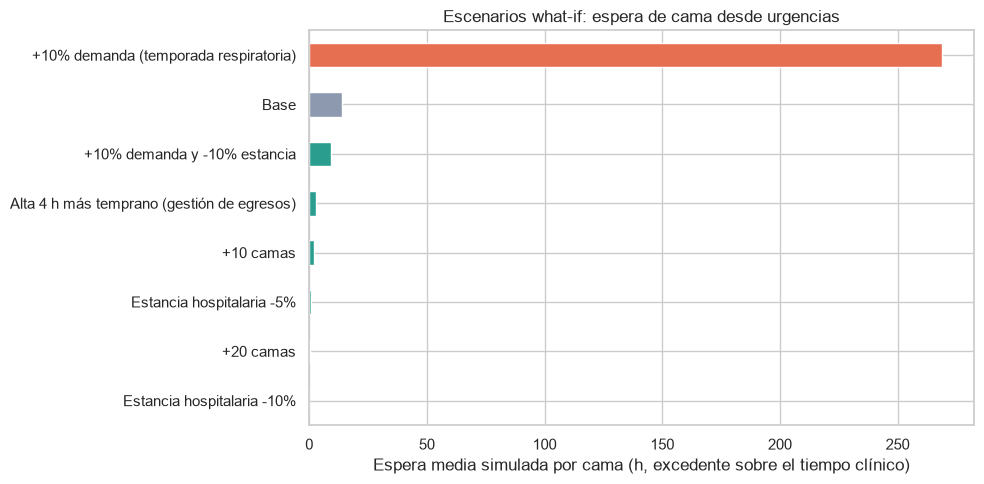

In [5]:
orden = res.espera_media_h.sort_values(); b0 = res.loc["Base", "espera_media_h"]
ax = orden.plot.barh(figsize=(10, 5), color=["#2a9d8f" if v < b0 - 1e-9 else ("#e76f51" if v > b0 + 1e-9 else "#8d99ae") for v in orden])
ax.set_xlabel("Espera media simulada por cama (h, excedente sobre el tiempo clínico)"); ax.set_title("Escenarios what-if: espera de cama desde urgencias")
guardar("06_escenarios")
res.rename_axis("escenario").reset_index().to_parquet(DATA_INTERIM / "escenarios.parquet", index=False)